# 05 — KNN « personnes similaires » (v2)

Objectif : passer de F1 macro ≈ 0,72 (v1) vers la cible demandée en testant, **toujours par validation croisée à 5 plis sur `X_ent`** :

1. poids par variable dans la distance (information mutuelle / coefficients de la logistique), exposant réglé par CV ;
2. pays dans la distance, poids réglé par CV, comparé à la version actuelle (pays hors distance) et à « même pays » ;
3. pondération des voisins par 1/distance ;
4. autres distances : Manhattan, cosinus, Gower ;
5. grille fine de k (50, 75, 100, 150, 200, 300) et de seuils ;
6. âge en tranches vs âge standardisé ;
7. seuil par pays et k par pays.

`X_val` n'est **pas** utilisé pour choisir : il sert seulement de contrôle indépendant à la fin, puis `X_test` pour le chiffre final.
Les poids « mi » / « logit » sont recalculés **dans chaque pli** sur la partie entraînement (pas de fuite).

In [101]:
import sys
sys.path.insert(0, "..")

import os, json, time
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.metrics import f1_score, accuracy_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold

import importlib
import src.voisins
importlib.reload(src.voisins)          # <- indispensable après chaque modif du .py
from src.voisins import entrainer, voisins, predire, calculer_voisinage, taux_par_k
from src.decoupage import decouper, evaluer

X_ent, X_val, X_test, y_ent, y_val, y_test = decouper()
y_e, y_v, y_t = np.asarray(y_ent), np.asarray(y_val), np.asarray(y_test)

print("Entraînement :", X_ent.shape, " Validation :", X_val.shape, " Test :", X_test.shape)
print("Colonnes :", list(X_ent.columns))
print("Type de y :", y_ent.dtype, "| valeurs :", np.unique(y_e), "| taux de positifs :", round(y_e.mean(), 3))

Entraînement : (16466, 10)  Validation : (3529, 10)  Test : (3529, 10)
Colonnes : ['country', 'location_type', 'cellphone_access', 'household_size', 'age_of_respondent', 'gender_of_respondent', 'relationship_with_head', 'marital_status', 'education_level', 'job_type']
Type de y : int64 | valeurs : [0 1] | taux de positifs : 0.141


In [102]:
# Contrôle rapide de l'API (inchangée) : entraîner en mémoire puis interroger un profil
objet_explo = entrainer(X_ent, y_ent, k=100, seuil=0.5)
print("OK, X_enc shape =", objet_explo["X_enc"].shape)
print(voisins(X_val.iloc[[0]], k=25, objet=objet_explo))   # -> {"k", "taux", "taux_meme_pays"}
print("NaN dans y_ent / y_val :", int(pd.isna(y_ent).sum()), "/", int(pd.isna(y_val).sum()))

OK, X_enc shape = (16466, 32)
{'k': 25, 'taux': 0.12, 'taux_meme_pays': 0.16}
NaN dans y_ent / y_val : 0 / 0


## **Choix de la distance**

Le KNN compare des profils : les catégorielles passent en one-hot, l'âge et la taille du ménage sont standardisés (sinon l'âge écraserait tout).
Mais « toutes les variables comptent autant » est faux pour la cible : l'éducation, l'emploi, le pays et le téléphone pèsent beaucoup plus.
La v2 permet donc (dans `src/voisins.py`) :

* un **poids par variable** (`poids_vars` : dict, `"mi"` ou `"logit"`, avec exposant `puissance`) ;
* le **pays dans la distance** (`poids_pays`) ;
* les distances `euclidean`, `manhattan`, `cosine` et **`gower`** (implémentée, pondérée) ;
* la moyenne pondérée par **1/(distance + eps)** (`weights="distance"`) ;
* l'**âge en tranches** (`age_mode="tranches"`), `k_pays` et `seuils_pays`.

## Outils de validation croisée (5 plis sur X_ent)

In [103]:
KS = [50, 75, 100, 150, 200, 300]
SEUILS = np.round(np.arange(0.05, 0.951, 0.025), 3)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
PLIS = list(skf.split(X_ent, y_e))
_cache = {}


def f1_macro(y, pred):
    y = np.asarray(y).astype(bool); p = np.asarray(pred).astype(bool)
    tp = np.sum(p & y); fp = np.sum(p & ~y); fn = np.sum(~p & y); tn = np.sum(~p & ~y)
    return 0.5 * (2 * tp / max(2 * tp + fp + fn, 1) + 2 * tn / max(2 * tn + fn + fp, 1))


def f1_macro_seuils(y, taux, seuils):
    y = np.asarray(y).astype(bool)[:, None]
    P = taux[:, None] >= np.asarray(seuils)[None, :]
    tp = (P & y).sum(0); fp = (P & ~y).sum(0); fn = (~P & y).sum(0); tn = (~P & ~y).sum(0)
    return 0.5 * (2 * tp / np.maximum(2 * tp + fp + fn, 1) + 2 * tn / np.maximum(2 * tn + fn + fp, 1))


def cv_oof(config, variante="global"):
    """Taux hors-pli pour chaque k de KS : tableau (n_ent, len(KS))."""
    cle = (json.dumps(config, sort_keys=True, default=str), variante)
    if cle not in _cache:
        T = np.zeros((len(X_ent), len(KS)))
        for tr, va in PLIS:
            obj = entrainer(X_ent.iloc[tr], y_e[tr], k=max(KS), **config)
            d, yv = calculer_voisinage(obj, X_ent.iloc[va], k_max=max(KS), variante=variante)
            T[va] = taux_par_k(d, yv, KS, obj["weights"], obj["eps"])
        _cache[cle] = T
    return _cache[cle]


def meilleur(T):
    """Meilleur (k, seuil) global sur les taux hors-pli."""
    M = np.array([f1_macro_seuils(y_e, T[:, j], SEUILS) for j in range(len(KS))])
    j, i = np.unravel_index(M.argmax(), M.shape)
    return {"f1": float(M[j, i]), "k": KS[j], "seuil": float(SEUILS[i])}, M


def ecart_plis(T, k, seuil):
    j = KS.index(k)
    return np.std([f1_macro(y_e[va], T[va, j] >= seuil) for _, va in PLIS])


RECAP = []


def comparer(titre, essais):
    """essais = {nom: (config, variante)} -> tableau trié, retourne (nom_gagnant, config, variante)."""
    lignes = []
    for nom, (cfg, var) in essais.items():
        t0 = time.time()
        b, _ = meilleur(cv_oof(cfg, var))
        lignes.append({"essai": nom, **b, "std_plis": ecart_plis(cv_oof(cfg, var), b["k"], b["seuil"]),
                       "s": round(time.time() - t0, 1)})
    df = pd.DataFrame(lignes).sort_values("f1", ascending=False).reset_index(drop=True)
    print(titre); print(df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
    g = df.iloc[0]["essai"]
    RECAP.append({"étape": titre, "gagnant": g, "f1_cv": df.iloc[0]["f1"]})
    return g, *essais[g]

## Étape 0 — Référence : la v1 sous validation croisée

In [104]:
essais = {
    "v1 (euclid., uniforme, pays hors distance) — tous pays": ({}, "global"),
    "v1 — même pays":                                          ({}, "meme_pays"),
}
_ = comparer("Étape 0 — v1 en CV 5 plis", essais)
F1_V1_CV = RECAP[-1]["f1_cv"]

Étape 0 — v1 en CV 5 plis
                                                 essai     f1  k  seuil  std_plis      s
                                        v1 — même pays 0.7195 50 0.2750    0.0022 4.4000
v1 (euclid., uniforme, pays hors distance) — tous pays 0.7127 75 0.2750    0.0034 7.5000


## Étape 1 — Distance et pondération des voisins (Manhattan, cosinus, Gower ; uniforme vs 1/distance)

In [105]:
essais = {}
for metric in ["euclidean", "manhattan", "cosine", "gower"]:
    essais[f"{metric} | uniform"]         = ({"metric": metric}, "global")
    essais[f"{metric} | distance eps=1e-6"] = ({"metric": metric, "weights": "distance", "eps": 1e-6}, "global")
    essais[f"{metric} | distance eps=0.3"]  = ({"metric": metric, "weights": "distance", "eps": 0.3}, "global")

g, CONFIG, VARIANTE = comparer("Étape 1 — distance × pondération", essais)
print("\n-> retenu :", g, CONFIG)

Étape 1 — distance × pondération
                        essai     f1   k  seuil  std_plis       s
     gower | distance eps=0.3 0.7137 200 0.2750    0.0073 30.8000
              gower | uniform 0.7134 150 0.2750    0.0069 27.4000
 manhattan | distance eps=0.3 0.7132 200 0.2500    0.0071  7.6000
          manhattan | uniform 0.7128 100 0.2750    0.0041  7.6000
 euclidean | distance eps=0.3 0.7127  75 0.2500    0.0046  6.6000
          euclidean | uniform 0.7127  75 0.2750    0.0034  6.2000
    cosine | distance eps=0.3 0.7122  75 0.2750    0.0051  5.1000
             cosine | uniform 0.7109 100 0.2500    0.0037  5.5000
    gower | distance eps=1e-6 0.6926 100 0.3500    0.0062 27.4000
manhattan | distance eps=1e-6 0.6915 200 0.2750    0.0050  7.5000
euclidean | distance eps=1e-6 0.6906 150 0.2500    0.0042  6.3000
   cosine | distance eps=1e-6 0.6757  75 0.2750    0.0022  5.6000

-> retenu : gower | distance eps=0.3 {'metric': 'gower', 'weights': 'distance', 'eps': 0.3}


## Étape 2 — Poids par variable (information mutuelle ou |coefficients| de la logistique)
`puissance` règle la force du poids : 0 = toutes égales (v1), 1 = poids bruts, 2-3 = on accentue les variables qui comptent.

In [106]:
essais = {"sans poids (acquis étape 1)": (CONFIG, "global")}
for source in ["mi", "logit"]:
    for p in [0.5, 1, 1.5, 2, 3]:
        essais[f"{source} puissance={p}"] = ({**CONFIG, "poids_vars": source, "puissance": p}, "global")

g, CONFIG, VARIANTE = comparer("Étape 2 — poids par variable", essais)
print("\n-> retenu :", g)

# poids effectivement appris (entraînement complet) pour lecture / partage
if "poids_vars" in CONFIG:
    o = entrainer(X_ent, y_e, **CONFIG)
    print(pd.Series(o["poids"]).sort_values(ascending=False).round(2))

Étape 2 — poids par variable
                      essai     f1   k  seuil  std_plis       s
        logit puissance=1.5 0.7194  50 0.3000    0.0042 39.8000
          logit puissance=2 0.7191  50 0.3000    0.0038 28.2000
          logit puissance=1 0.7188  50 0.3000    0.0052 28.1000
             mi puissance=3 0.7180  50 0.3000    0.0052 28.8000
             mi puissance=1 0.7173  50 0.3000    0.0061 28.6000
        logit puissance=0.5 0.7172  50 0.3000    0.0070 28.1000
          logit puissance=3 0.7172  50 0.3000    0.0044 31.4000
             mi puissance=2 0.7166  50 0.3000    0.0049 29.2000
           mi puissance=0.5 0.7166  50 0.3000    0.0039 30.2000
           mi puissance=1.5 0.7161  50 0.3250    0.0061 29.7000
sans poids (acquis étape 1) 0.7137 200 0.2750    0.0073  0.1000

-> retenu : logit puissance=1.5
job_type                  3.10
education_level           2.74
cellphone_access          1.87
location_type             0.99
relationship_with_head    0.92
gender_of_respo

## Étape 3 — Le pays dans la distance (poids réglé par CV) vs version actuelle vs « même pays »
`poids_pays=None` = v1 (pays hors distance). Un poids élevé rapproche le comportement de « même pays » tout en gardant les voisins des autres pays si le poids est modéré.

In [107]:
essais = {"pays hors distance (v1)": (CONFIG, "global"),
          "même pays (index séparés)": (CONFIG, "meme_pays")}
for w in [0.5, 1, 2, 4, 8]:
    essais[f"pays dans la distance, poids={w}"] = ({**CONFIG, "poids_pays": w}, "global")

g, CONFIG, VARIANTE = comparer("Étape 3 — pays", essais)
print("\n-> retenu :", g, "| variante :", VARIANTE)

Étape 3 — pays
                           essai     f1  k  seuil  std_plis       s
  pays dans la distance, poids=1 0.7261 50 0.3250    0.0033 46.1000
  pays dans la distance, poids=2 0.7255 50 0.3250    0.0030 45.0000
       même pays (index séparés) 0.7247 50 0.3250    0.0021  9.0000
  pays dans la distance, poids=4 0.7233 50 0.3250    0.0018 41.7000
pays dans la distance, poids=0.5 0.7230 50 0.3250    0.0039 34.4000
  pays dans la distance, poids=8 0.7227 50 0.3250    0.0024 40.9000
         pays hors distance (v1) 0.7194 50 0.3000    0.0042  0.1000

-> retenu : pays dans la distance, poids=1 | variante : global


## Étape 4 — Âge en tranches vs âge standardisé

In [108]:
essais = {"âge standardisé": (CONFIG, VARIANTE),
          "âge en tranches": ({**CONFIG, "age_mode": "tranches"}, VARIANTE)}
if CONFIG.get("metric") == "gower":
    print("NB : Gower utilise l'âge numérique normalisé (min-max) ; age_mode y est sans effet.")
    print("     On teste donc aussi les tranches d'âge avec une distance euclidienne (mêmes poids).")
    base_eu = {**CONFIG, "metric": "euclidean"}
    essais["euclidienne, âge standardisé"] = (base_eu, VARIANTE)
    essais["euclidienne, âge en tranches"] = ({**base_eu, "age_mode": "tranches"}, VARIANTE)
g, CONFIG, VARIANTE = comparer("Étape 4 — encodage de l'âge", essais)
print("\n-> retenu :", g)

NB : Gower utilise l'âge numérique normalisé (min-max) ; age_mode y est sans effet.
     On teste donc aussi les tranches d'âge avec une distance euclidienne (mêmes poids).
Étape 4 — encodage de l'âge
                       essai     f1  k  seuil  std_plis       s
euclidienne, âge standardisé 0.7279 75 0.3250    0.0043  6.7000
euclidienne, âge en tranches 0.7278 75 0.3250    0.0070  7.0000
             âge en tranches 0.7261 50 0.3250    0.0033 43.3000
             âge standardisé 0.7261 50 0.3250    0.0033  0.1000

-> retenu : euclidienne, âge standardisé


## Étape 5 — Grille fine de k et de seuil (globaux)

Meilleur global : {'f1': 0.7279106845706371, 'k': 75, 'seuil': 0.325} | écart-type entre plis : 0.0043


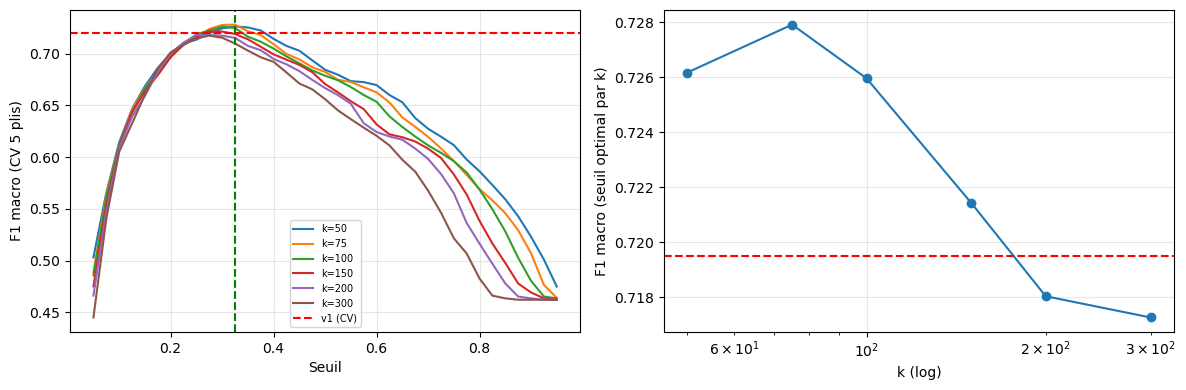

In [109]:
T_cv = cv_oof(CONFIG, VARIANTE)
best, M = meilleur(T_cv)
K_RETENU, SEUIL_RETENU = best["k"], best["seuil"]
RECAP.append({"étape": "Étape 5 — k et seuil globaux", "gagnant": f"k={K_RETENU}, seuil={SEUIL_RETENU}", "f1_cv": best["f1"]})
print("Meilleur global :", best, "| écart-type entre plis :", round(ecart_plis(T_cv, K_RETENU, SEUIL_RETENU), 4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for j, k in enumerate(KS):
    ax[0].plot(SEUILS, M[j], label=f"k={k}")
ax[0].axvline(SEUIL_RETENU, color="green", ls="--"); ax[0].axhline(F1_V1_CV, color="red", ls="--", label="v1 (CV)")
ax[0].set_xlabel("Seuil"); ax[0].set_ylabel("F1 macro (CV 5 plis)"); ax[0].legend(fontsize=7); ax[0].grid(alpha=.3)
ax[1].plot(KS, M.max(axis=1), marker="o"); ax[1].axhline(F1_V1_CV, color="red", ls="--")
ax[1].set_xscale("log"); ax[1].set_xlabel("k (log)"); ax[1].set_ylabel("F1 macro (seuil optimal par k)"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## Étape 6 — Seuil par pays et k par pays
Recherche par coordonnées sur les taux hors-pli (on améliore le F1 macro global pays par pays).
Garde-fou anti-surapprentissage : les réglages sont appris sur une moitié de `X_ent` et testés sur l'autre moitié (dans les deux sens) ;
on ne garde la version par pays que si elle gagne sur la moitié non vue.

In [110]:
pays_e = X_ent["country"].reset_index(drop=True)


def optimiser_par_pays(y, T, pays, k0, s0, optim_k=True, passes=3):
    cs = list(pays.unique()); rows = {c: (pays == c).to_numpy() for c in cs}
    kc = {c: k0 for c in cs}; sc = {c: s0 for c in cs}

    def pred(kc, sc):
        p = np.zeros(len(y), dtype=bool)
        for c in cs:
            p[rows[c]] = T[rows[c], KS.index(kc[c])] >= sc[c]
        return p

    cour = f1_macro(y, pred(kc, sc))
    for _ in range(passes):
        change = False
        for c in cs:
            for k in (KS if optim_k else [k0]):
                for s in SEUILS:
                    kc2, sc2 = {**kc, c: k}, {**sc, c: float(s)}
                    f = f1_macro(y, pred(kc2, sc2))
                    if f > cour + 1e-9:
                        cour, kc, sc, change = f, kc2, sc2, True
        if not change:
            break
    return kc, sc, cour, pred


rng = np.random.default_rng(0)
moitie = rng.random(len(y_e)) < 0.5
gains = {"seuils": [], "seuils+k": []}
for A, B in [(moitie, ~moitie), (~moitie, moitie)]:
    base = f1_macro(y_e[B], T_cv[B, KS.index(K_RETENU)] >= SEUIL_RETENU)
    for nom, optim_k in [("seuils", False), ("seuils+k", True)]:
        kc, sc, _, _ = optimiser_par_pays(y_e[A], T_cv[A], pays_e[A].reset_index(drop=True), K_RETENU, SEUIL_RETENU, optim_k)
        pB = np.zeros(B.sum(), dtype=bool); pa = pays_e[B].to_numpy(); TB = T_cv[B]
        for c in kc:
            m = pa == c; pB[m] = TB[m, KS.index(kc[c])] >= sc[c]
        gains[nom].append(f1_macro(y_e[B], pB) - base)
print("Gain sur moitié non vue (F1 macro) :", {k: np.round(v, 4) for k, v in gains.items()})

UTILISER_SEUILS_PAYS = np.mean(gains["seuils"]) > 0.001
UTILISER_K_PAYS = np.mean(gains["seuils+k"]) > np.mean(gains["seuils"]) + 0.001

kc, sc, f1_pays, _ = optimiser_par_pays(y_e, T_cv, pays_e, K_RETENU, SEUIL_RETENU, optim_k=UTILISER_K_PAYS)
SEUILS_PAYS = sc if UTILISER_SEUILS_PAYS else {}
K_PAYS = kc if (UTILISER_SEUILS_PAYS and UTILISER_K_PAYS) else {}
print("Seuils par pays retenus :", SEUILS_PAYS or "non (gain non confirmé)")
print("k par pays retenus      :", K_PAYS or "non (gain non confirmé)")
if SEUILS_PAYS:
    RECAP.append({"étape": "Étape 6 — seuils/k par pays", "gagnant": "oui", "f1_cv": f1_pays})
    print("F1 macro CV avec réglages par pays (optimiste, appris sur tout X_ent) :", round(f1_pays, 4))

Gain sur moitié non vue (F1 macro) : {'seuils': array([0.0013, 0.0011]), 'seuils+k': array([-0.0027,  0.0004])}
Seuils par pays retenus : {'Rwanda': 0.275, 'Uganda': 0.3, 'Tanzania': 0.325, 'Kenya': 0.3}
k par pays retenus      : non (gain non confirmé)
F1 macro CV avec réglages par pays (optimiste, appris sur tout X_ent) : 0.7296


## Bilan CV et contrôle sur `X_val` (non utilisé pour choisir)

In [111]:
print(pd.DataFrame(RECAP).to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("\nConfig retenue :", CONFIG, "| variante :", VARIANTE, "| k =", K_RETENU, "| seuil =", SEUIL_RETENU)

# v1 vs v2 sur X_val
v1 = entrainer(X_ent, y_e, k=100, seuil=0.30)
yp1, _ = predire(X_val, v1, variante="global")
v2 = entrainer(X_ent, y_e, k=K_RETENU, seuil=SEUIL_RETENU, seuils_pays=SEUILS_PAYS, k_pays=K_PAYS, **CONFIG)
v2["variante"] = VARIANTE
yp2, tx2 = predire(X_val, v2)
print(f"\nX_val — v1 : F1 macro = {f1_score(y_v, yp1, average='macro'):.4f}"
      f" | v2 : F1 macro = {f1_score(y_v, yp2, average='macro'):.4f}"
      f" | accuracy = {accuracy_score(y_v, yp2):.4f} | AUC (taux) = {roc_auc_score(y_v, tx2):.4f}")

                           étape                        gagnant  f1_cv
       Étape 0 — v1 en CV 5 plis                 v1 — même pays 0.7195
Étape 1 — distance × pondération       gower | distance eps=0.3 0.7137
    Étape 2 — poids par variable            logit puissance=1.5 0.7194
                  Étape 3 — pays pays dans la distance, poids=1 0.7261
     Étape 4 — encodage de l'âge   euclidienne, âge standardisé 0.7279
    Étape 5 — k et seuil globaux              k=75, seuil=0.325 0.7279
     Étape 6 — seuils/k par pays                            oui 0.7296

Config retenue : {'metric': 'euclidean', 'weights': 'distance', 'eps': 0.3, 'poids_vars': 'logit', 'puissance': 1.5, 'poids_pays': 1} | variante : global | k = 75 | seuil = 0.325

X_val — v1 : F1 macro = 0.7195 | v2 : F1 macro = 0.7258 | accuracy = 0.8629 | AUC (taux) = 0.8605


## Sauvegarde du modèle livré

In [112]:
objet = entrainer(X_ent, y_ent, k=K_RETENU, seuil=SEUIL_RETENU,
                  seuils_pays=SEUILS_PAYS, k_pays=K_PAYS, **CONFIG)
objet["variante"] = VARIANTE

os.makedirs("../models", exist_ok=True)
joblib.dump(objet, "../models/voisins.joblib", compress=3)
print("Modèle sauvegardé dans models/voisins.joblib")

# réglages lisibles, à partager (Loan, Oscar)
reglages = {"config": CONFIG, "variante": VARIANTE, "k": K_RETENU, "seuil": SEUIL_RETENU,
            "seuils_pays": SEUILS_PAYS, "k_pays": K_PAYS,
            "f1_macro_cv_v1": round(F1_V1_CV, 4), "f1_macro_cv_v2": round(best["f1"], 4)}
with open("../models/reglages_knn.json", "w", encoding="utf-8") as f:
    json.dump(reglages, f, ensure_ascii=False, indent=2, default=float)
print(json.dumps(reglages, ensure_ascii=False, indent=2, default=float))

Modèle sauvegardé dans models/voisins.joblib
{
  "config": {
    "metric": "euclidean",
    "weights": "distance",
    "eps": 0.3,
    "poids_vars": "logit",
    "puissance": 1.5,
    "poids_pays": 1
  },
  "variante": "global",
  "k": 75,
  "seuil": 0.325,
  "seuils_pays": {
    "Rwanda": 0.275,
    "Uganda": 0.3,
    "Tanzania": 0.325,
    "Kenya": 0.3
  },
  "k_pays": {},
  "f1_macro_cv_v1": 0.7195,
  "f1_macro_cv_v2": 0.7279
}


In [113]:
# Vérification finale du contenu du joblib livré
obj = joblib.load("../models/voisins.joblib")
print("k livré     :", obj["k"], "| seuil livré :", obj["seuil"])
print("seuils pays :", obj["seuils_pays"], "| k pays :", obj["k_pays"])
assert obj["k"] == K_RETENU, f"k livré {obj['k']} != K_RETENU {K_RETENU}"
assert abs(obj["seuil"] - SEUIL_RETENU) < 1e-9, f"seuil livré {obj['seuil']} != SEUIL_RETENU {SEUIL_RETENU}"
assert obj["seuils_pays"] == {p: float(s) for p, s in SEUILS_PAYS.items()}
assert obj["k_pays"] == {p: int(k) for p, k in K_PAYS.items()}
print("OK — joblib cohérent avec le notebook.")

k livré     : 75 | seuil livré : 0.325
seuils pays : {'Rwanda': 0.275, 'Uganda': 0.3, 'Tanzania': 0.325, 'Kenya': 0.3} | k pays : {}
OK — joblib cohérent avec le notebook.


## Évaluation finale sur le test

In [114]:
y_pred_test, taux_test = predire(X_test, objet=obj)

resultats_test = evaluer(X_test, y_test, y_pred_test)
print(resultats_test)

print("\nF1 macro test       :", round(f1_score(y_t, y_pred_test, average="macro"), 4))
print("F1 classe positive  :", round(f1_score(y_t, y_pred_test), 4))
print("Accuracy            :", round(accuracy_score(y_t, y_pred_test), 4))
print("AUC (taux KNN)      :", round(roc_auc_score(y_t, taux_test), 4))
print("Rappel : cible demandée = 0,90 ; préciser avec le responsable quelle métrique est visée.")

                               effectif  f1_macro
groupe                                           
Global                             3529    0.7384
country = Kenya                     910    0.7059
country = Rwanda                   1311    0.7020
country = Tanzania                  993    0.7879
country = Uganda                    315    0.7546
gender_of_respondent = Female      2049    0.7279
gender_of_respondent = Male        1480    0.7398

F1 macro test       : 0.7384
F1 classe positive  : 0.5527
Accuracy            : 0.8702
AUC (taux KNN)      : 0.8559
Rappel : cible demandée = 0,90 ; préciser avec le responsable quelle métrique est visée.


## À partager avec Loan et Oscar

In [115]:
print(f"""Réglages KNN v2 (CV 5 plis sur X_ent) — fichier models/reglages_knn.json
- F1 macro CV : v1 = {F1_V1_CV:.3f} -> v2 = {best['f1']:.3f}
- Config : {CONFIG} | variante : {VARIANTE} | k = {K_RETENU} | seuil = {SEUIL_RETENU}
- Seuils par pays : {SEUILS_PAYS or 'non retenus'} | k par pays : {K_PAYS or 'non retenus'}
- Les poids de variables (poids_vars) sont recalculés sur le train de chaque pli ; reprenez les seuils par pays
  seulement s'ils améliorent aussi votre F1 sur une moitié de X_ent non vue.""")

Réglages KNN v2 (CV 5 plis sur X_ent) — fichier models/reglages_knn.json
- F1 macro CV : v1 = 0.720 -> v2 = 0.728
- Config : {'metric': 'euclidean', 'weights': 'distance', 'eps': 0.3, 'poids_vars': 'logit', 'puissance': 1.5, 'poids_pays': 1} | variante : global | k = 75 | seuil = 0.325
- Seuils par pays : {'Rwanda': 0.275, 'Uganda': 0.3, 'Tanzania': 0.325, 'Kenya': 0.3} | k par pays : non retenus
- Les poids de variables (poids_vars) sont recalculés sur le train de chaque pli ; reprenez les seuils par pays
  seulement s'ils améliorent aussi votre F1 sur une moitié de X_ent non vue.


## Modèle déployé : réentraînement sur 85 %

Règle du groupe : le test ci-dessus est mesuré avec le modèle appris sur `X_ent` (70 %), c'est ce chiffre qui va dans le rapport. Le modèle déployé apprend ensuite sur entraînement + validation (85 %), avec exactement les mêmes réglages. Le test reste fermé.

In [ ]:
import src.voisins as module_voisins

objet_deploye = entrainer(pd.concat([X_ent, X_val]), pd.concat([y_ent, y_val]), k=K_RETENU, seuil=SEUIL_RETENU,
                          seuils_pays=SEUILS_PAYS, k_pays=K_PAYS, **CONFIG)
objet_deploye["variante"] = VARIANTE
joblib.dump(objet_deploye, module_voisins.CHEMIN_MODELE, compress=3)
module_voisins.charger_modele.cache_clear()  # pour relire le fichier qui vient d'être enregistré

resultat = voisins(X_test.iloc[[0]])
assert set(resultat) == {"k", "taux", "taux_meme_pays"}
print(f"Modèle déployé : {len(objet_deploye['y'])} personnes (85 %)", resultat)